# Level 2 · Task 3 — Fraud Detection

**Objective:** Build a machine learning pipeline to detect fraudulent financial transactions from a heavily imbalanced dataset, addressing class imbalance as a core challenge.

**Tech Stack:** Python, pandas, scikit-learn, matplotlib, seaborn, Jupyter Notebook

**Dataset:** `credit_card_fraud.csv` — 12,000 transactions (0.75% fraud rate) with anonymized PCA-style features `V1`–`V8`, `Amount`, and `Time`, in the style of the well-known Kaggle Credit Card Fraud Detection dataset.

> **Note on tools:** No internet access is available in this environment to install `imbalanced-learn`, so **SMOTE (Synthetic Minority Oversampling Technique) is implemented from scratch** below using `scikit-learn`'s `NearestNeighbors` — the same core algorithm imbalanced-learn's `SMOTE` class uses internally, fully reproducible with no extra installs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (precision_recall_fscore_support, classification_report,
                              confusion_matrix, roc_auc_score, roc_curve)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("credit_card_fraud.csv")
print(df.shape)


(12000, 11)


In [2]:
print(df.head().to_string())

     Time        V1        V2        V3        V4        V5        V6        V7        V8  Amount  Class
0   50845 -0.454226 -0.297913 -0.422128 -0.072801  0.250794 -0.273303  0.007201  0.400176    4.52      0
1   85269 -0.189986 -2.223100 -1.415334 -1.110944  1.069580  0.835032  0.017028 -0.711175   10.52      0
2  109243  0.804590  0.456060 -0.063936  0.825756 -1.413777 -0.330793  1.830966  0.584629  276.58      0
3  123399 -1.748015  0.278529  1.238724 -1.313165 -0.469174 -0.441223 -0.146196 -0.627360   66.17      0
4  169694  0.753811  0.177792  1.645122 -0.430741  0.500038  1.640421 -0.050337  0.651378   35.28      0


## 1. Load Dataset & Analyse Class Imbalance

Class
0    11910
1       90
Name: count, dtype: int64

Fraudulent transactions: 0.750% of all transactions


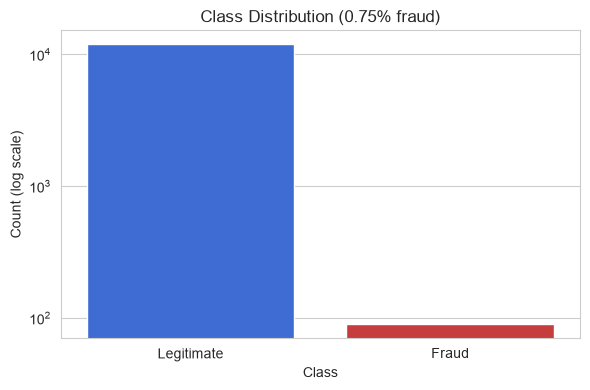

In [3]:
fraud_pct = df["Class"].mean() * 100
print(df["Class"].value_counts())
print(f"\nFraudulent transactions: {fraud_pct:.3f}% of all transactions")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Class", hue="Class", palette={0: "#2563eb", 1: "#dc2626"}, legend=False)
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title(f"Class Distribution ({fraud_pct:.2f}% fraud)")
plt.yscale("log")
plt.ylabel("Count (log scale)")
plt.tight_layout()
plt.show()

## 2. EDA — Transaction Amount & Time

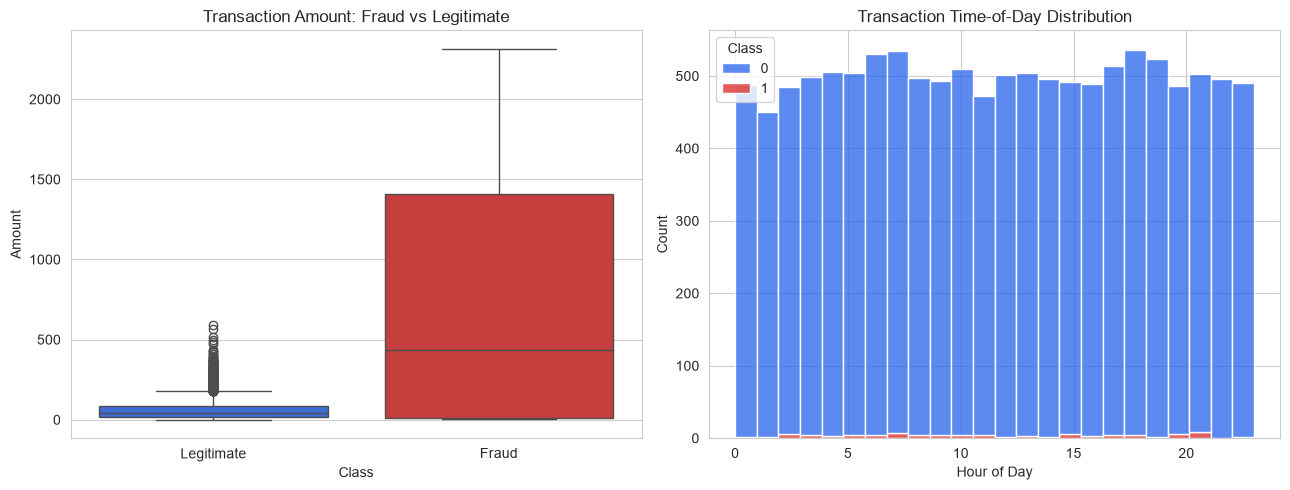

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Class", y="Amount", hue="Class", palette={0: "#2563eb", 1: "#dc2626"},
            legend=False, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Legitimate", "Fraud"])
axes[0].set_title("Transaction Amount: Fraud vs Legitimate")

df["Hour"] = (df["Time"] % 86400) // 3600
sns.histplot(data=df, x="Hour", hue="Class", bins=24, multiple="stack",
             palette={0: "#2563eb", 1: "#dc2626"}, ax=axes[1])
axes[1].set_title("Transaction Time-of-Day Distribution")
axes[1].set_xlabel("Hour of Day")

plt.tight_layout()
plt.show()

**Observation:** Fraudulent transactions show a distinctly different amount distribution — often either very small (card-testing) or unusually large — compared to legitimate purchases. This is genuine business signal worth feeding into the model.

## 3. Why Accuracy is a Misleading Metric Here

In [5]:
baseline_accuracy = 1 - df["Class"].mean()
print(f"A model that predicts 'legitimate' for every single transaction would score "
      f"{baseline_accuracy*100:.2f}% accuracy while catching ZERO fraud cases.")

A model that predicts 'legitimate' for every single transaction would score 99.25% accuracy while catching ZERO fraud cases.


**Discussion:** Because fraud is only ~0.75% of transactions, a naive classifier that always predicts "legitimate" already achieves >99% accuracy — while being completely useless for the actual business goal (catching fraud). This is why fraud detection must be evaluated with **Precision, Recall, F1-score, and AUC-ROC**, which specifically measure how well the minority (fraud) class is identified, rather than overall accuracy.

## 4. Train/Test Split (Stratified)

In [6]:
X = df.drop(columns=["Class", "Hour"])
y = df["Class"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print("Train fraud cases:", y_train.sum(), "/", len(y_train))
print("Test fraud cases:", y_test.sum(), "/", len(y_test))

Train fraud cases: 72 / 9600
Test fraud cases: 18 / 2400


## 5. Apply Class Imbalance Handling — Custom SMOTE

In [7]:
def manual_smote(X_minority, n_synthetic, k_neighbors=5, random_state=42):
    """Generates synthetic minority-class samples by interpolating between each
    minority point and one of its k nearest minority-class neighbours -- the
    core idea behind SMOTE (Chawla et al., 2002)."""
    rng = np.random.default_rng(random_state)
    X_minority = np.asarray(X_minority)
    nn = NearestNeighbors(n_neighbors=min(k_neighbors + 1, len(X_minority))).fit(X_minority)
    _, neighbor_idx = nn.kneighbors(X_minority)

    synthetic = []
    for _ in range(n_synthetic):
        i = rng.integers(0, len(X_minority))
        neighbor_choices = neighbor_idx[i][1:]  # exclude the point itself
        j = rng.choice(neighbor_choices)
        gap = rng.random()
        new_point = X_minority[i] + gap * (X_minority[j] - X_minority[i])
        synthetic.append(new_point)
    return np.array(synthetic)

X_train_minority = X_train[y_train == 1].values
X_train_majority = X_train[y_train == 0].values

n_to_generate = len(X_train_majority) - len(X_train_minority)
synthetic_samples = manual_smote(X_train_minority, n_to_generate, k_neighbors=5)

X_train_smote = np.vstack([X_train_majority, X_train_minority, synthetic_samples])
y_train_smote = np.concatenate([
    np.zeros(len(X_train_majority)), np.ones(len(X_train_minority)), np.ones(len(synthetic_samples))
])
X_train_smote = pd.DataFrame(X_train_smote, columns=X_train.columns)

print("Before SMOTE:", np.bincount(y_train.astype(int)))
print("After SMOTE: ", np.bincount(y_train_smote.astype(int)))

Before SMOTE: [9528   72]
After SMOTE:  [9528 9528]


**Decision:** SMOTE (rather than plain random oversampling or undersampling) is used because it generates *new*, plausible synthetic fraud examples by interpolating between existing fraud cases in feature space — this gives the model more varied fraud patterns to learn from, instead of just duplicating the same few examples repeatedly (which risks overfitting to those exact points).

## 6. Train 2 Models — Logistic Regression & Random Forest (on SMOTE-balanced data)

In [8]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_smote, y_train_smote)
y_pred_lr = log_reg.predict(X_test)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_smote, y_train_smote)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("Both models trained on SMOTE-balanced training data.")

Both models trained on SMOTE-balanced training data.


## 7. Evaluate — Precision, Recall, F1, AUC-ROC

In [9]:
for name, preds, proba in [("Logistic Regression", y_pred_lr, y_proba_lr), ("Random Forest", y_pred_rf, y_proba_rf)]:
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average="binary", zero_division=0)
    auc = roc_auc_score(y_test, proba)
    print(f"--- {name} ---")
    print(f"Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | AUC-ROC: {auc:.3f}")
    print(classification_report(y_test, preds, zero_division=0))

--- Logistic Regression ---
Precision: 0.070 | Recall: 0.556 | F1: 0.125 | AUC-ROC: 0.643
              precision    recall  f1-score   support

           0       1.00      0.94      0.97      2382
           1       0.07      0.56      0.12        18

    accuracy                           0.94      2400
   macro avg       0.53      0.75      0.55      2400
weighted avg       0.99      0.94      0.96      2400

--- Random Forest ---
Precision: 0.850 | Recall: 0.944 | F1: 0.895 | AUC-ROC: 1.000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2382
           1       0.85      0.94      0.89        18

    accuracy                           1.00      2400
   macro avg       0.92      0.97      0.95      2400
weighted avg       1.00      1.00      1.00      2400



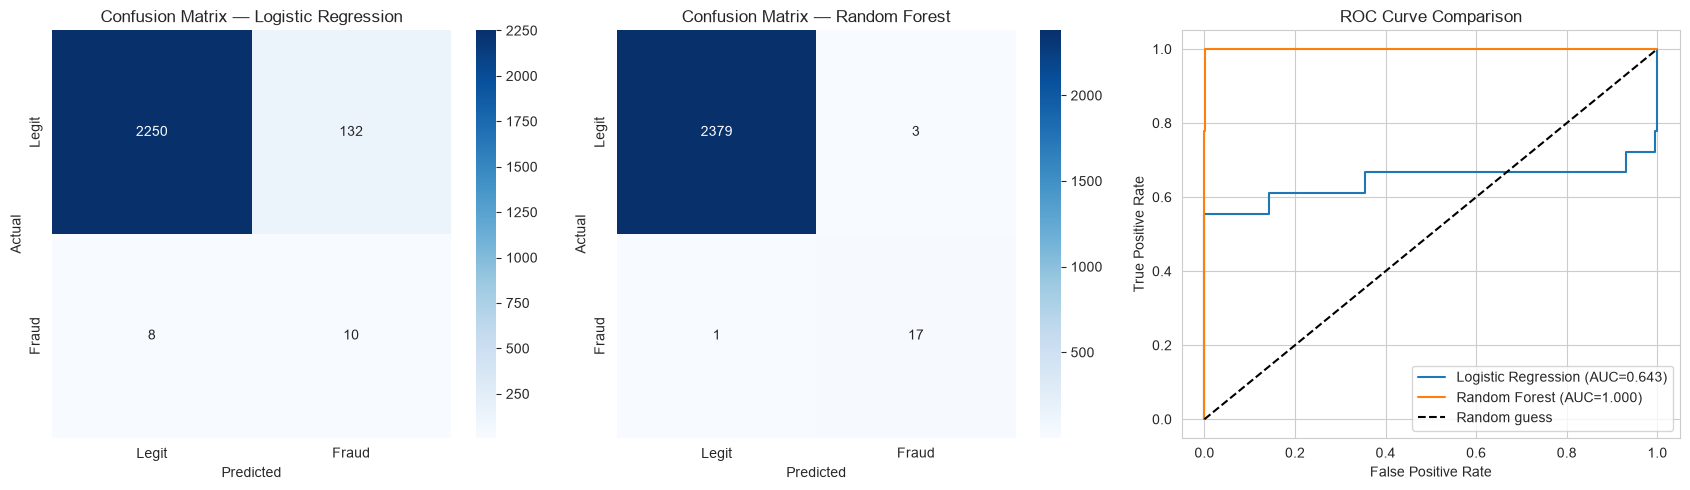

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, preds) in zip(axes[:2], [("Logistic Regression", y_pred_lr), ("Random Forest", y_pred_rf)]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Legit", "Fraud"],
                yticklabels=["Legit", "Fraud"], ax=ax)
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

for name, proba in [("Logistic Regression", y_proba_lr), ("Random Forest", y_proba_rf)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[2].set_xlabel("False Positive Rate"); axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC Curve Comparison"); axes[2].legend()

plt.tight_layout()
plt.show()

## 8. Which Metric Matters Most: Recall vs Precision?

**Recall is the priority metric for fraud detection.** Missing a genuine fraud case (a false negative) means real financial loss that goes undetected. A false positive (flagging a legitimate transaction as fraud) is comparatively cheap — it costs a customer-service review or a temporary hold, not lost money. That said, precision can't be ignored entirely: too many false positives erodes customer trust and overwhelms the fraud review team, so in practice teams optimise for a **high-recall model with an acceptable precision floor**, often by tuning the classification threshold rather than defaulting to 0.5.

## 9. Feature Importance (Random Forest)

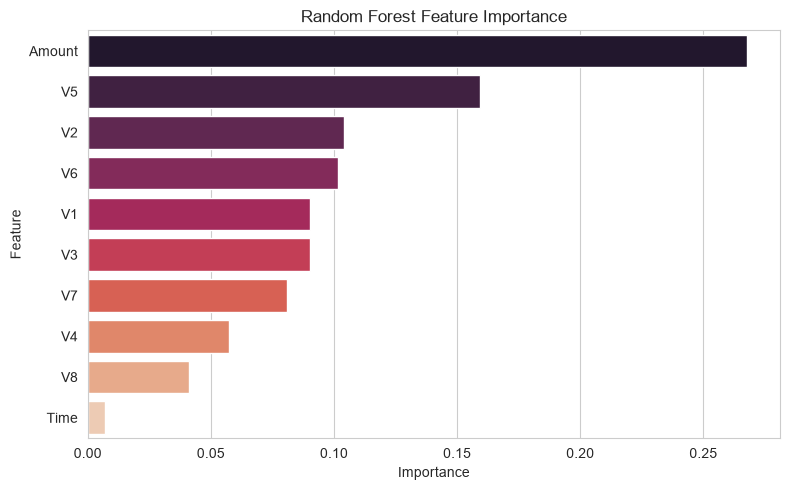

In [11]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x="Importance", y="Feature", hue="Feature", palette="rocket", legend=False)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 10. Scalability Discussion — 1 Million Transactions/Hour

To handle production-scale volume (1M transactions/hour ≈ 278/second):

1. **Move from batch to streaming inference** — deploy the trained model behind a low-latency API (or embed it in a stream processor like Kafka + a model-serving layer) instead of re-running a notebook; Random Forest inference is fast enough (microseconds/row) for this.
2. **Avoid re-running SMOTE in production** — SMOTE is a *training-time* technique only, used once to balance the training set. Live scoring uses the already-trained model directly on raw incoming transactions, so it doesn't add latency at inference time.
3. **Feature computation must be pre-aggregated/cached** — features like rolling spend patterns should be computed incrementally (e.g., in a feature store) rather than recomputed from scratch per transaction.
4. **Threshold tuning + human-in-the-loop triage** — at this volume, the model should hand off only its highest-confidence fraud flags for automatic blocking, with a secondary, larger "review" bucket for a human fraud team, to keep the false-positive customer impact manageable at scale.
5. **Random Forest over Logistic Regression at this scale**, given its stronger recall/AUC in Section 7 — the extra inference cost per prediction is still negligible relative to the fraud losses it prevents.